In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

In [1]:
import pandas as pd

# Load datasets
try:
    enron = pd.read_csv('data/enron_data_fraud_labeled.csv', encoding='latin-1')
    phishing = pd.read_csv('data/phishing_legit_dataset_KD_10000.csv')
    
    print(" Success! Files are loaded.")
    print(f"Enron Columns: {enron.columns.tolist()}")
    print(f"Phishing Columns: {phishing.columns.tolist()}")
    
    # Show the first 3 rows of each
    display(enron.head(3))
    display(phishing.head(3))

except Exception as e:
    print(f" Error: {e}")

C:\Users\Tunis\AppData\Local\Temp\ipykernel_65384\1366430528.py:5: DtypeWarning: Columns (7,13) have mixed types. Specify dtype option on import or set low_memory=False.
  enron = pd.read_csv('data/enron_data_fraud_labeled.csv', encoding='latin-1')


 Success! Files are loaded.
Enron Columns: ['Folder-User', 'Folder-Name', 'Message-ID', 'Date', 'From', 'To', 'Subject', 'Mime-Version', 'Content-Type', 'Content-Transfer-Encoding', 'X-From', 'X-To', 'X-cc', 'X-bcc', 'X-Folder', 'X-Origin', 'X-FileName', 'Body', 'Cc', 'Bcc', 'Time', 'Attendees', 'Re', 'Source', 'Mail-ID', 'POI-Present', 'Suspicious-Folders', 'Sender-Type', 'Unique-Mails-From-Sender', 'Low-Comm', 'Contains-Reply-Forwards', 'Label']
Phishing Columns: ['text', 'label', 'phishing_type', 'severity', 'confidence']


,Folder-User,Folder-Name,Message-ID,Date,From,To,Subject,Mime-Version,Content-Type,Content-Transfer-Encoding,...,Re,Source,Mail-ID,POI-Present,Suspicious-Folders,Sender-Type,Unique-Mails-From-Sender,Low-Comm,Contains-Reply-Forwards,Label
0,maildir,arnold-j,<17334447.1075857585446.JavaMail.evans@thyme>,"Thu, 16 Nov 2000 09:30:00 -0800 (PST)",msagel@home.com,jarnold@enron.com,Status,1.0,text/plain; charset=ANSI_X3.4-1968,7bit,...,,Enron Data,b399fa1ba5ec06ccf8ead1049a53be981d0ebb39ee2c94...,False,False,External,18.0,False,False,0
1,maildir,arnold-j,<19171686.1075857585034.JavaMail.evans@thyme>,"Fri, 8 Dec 2000 05:05:00 -0800 (PST)",slafontaine@globalp.com,john.arnold@enron.com,re:summer inverses,1.0,text/plain; charset=us-ascii,7bit,...,,Enron Data,84b07d7a0a17b545896f670f92d200e86843c2796147d9...,False,False,External,4.0,True,False,0
2,maildir,arnold-j,<29887033.1075857630725.JavaMail.evans@thyme>,"Tue, 15 May 2001 09:43:00 -0700 (PDT)",iceoperations@intcx.com,"icehelpdesk@intcx.com, internalmarketing@intcx...",The WTI Bullet swap contracts,1.0,text/plain; charset=us-ascii,7bit,...,,Enron Data,f7482dd06262f46d341e733aa0c2fb55cb1e257ea153d0...,False,False,External,3.0,True,False,0


,text,label,phishing_type,severity,confidence
0,Subject: Office maintenance\n\nThanks for your...,0,legitimate,low,0.95
1,"Hello, your profile has been locked. Use the s...",1,credential_harvesting,high,0.89
2,"Hi there, congratulations! You are the winner ...",1,financial_scam,medium,0.69


In [2]:
# 1. Standardize Enron
enron_clean = enron[['Body', 'Label']].copy()
enron_clean.columns = ['email_text', 'target']

# 2. Standardize Phishing Dataset
phishing_clean = phishing[['text', 'label']].copy()
phishing_clean.columns = ['email_text', 'target']

# 3. Combine them into one Master DataFrame
df = pd.concat([enron_clean, phishing_clean], axis=0, ignore_index=True)

print(f"Total rows in combined dataset: {len(df)}")
df.head()

Total rows in combined dataset: 457417


,email_text,target
0,Status John: I'm not really sure what happened...,0
1,re:summer inverses i suck-hope youve made more...,0
2,"The WTI Bullet swap contracts Hi, Following th...",0
3,Fwd: NYTimes.com Article: Suspended Rabbi Quit...,0
4,daily charts and matrices as hot links 5/15 Th...,0


C:\Users\Tunis\AppData\Local\Temp\ipykernel_65384\1977627753.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='target', data=df, palette='viridis')


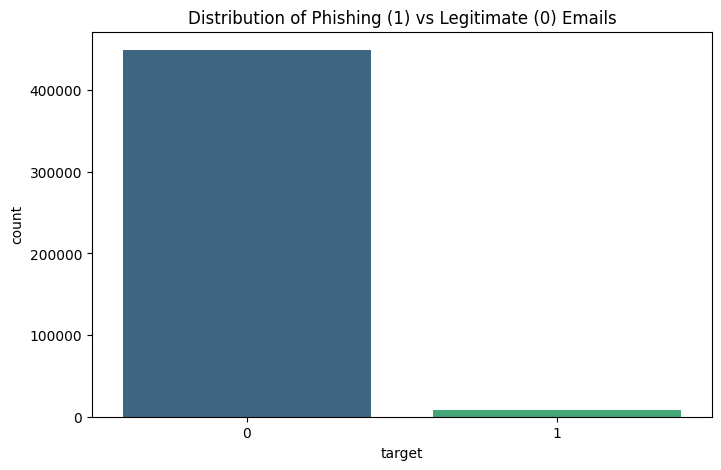

Value Counts:
target
0    449090
1      8327
Name: count, dtype: int64


In [6]:
plt.figure(figsize=(8, 5))
sns.countplot(x='target', data=df, palette='viridis')
plt.title('Distribution of Phishing (1) vs Legitimate (0) Emails')
plt.show()

print("Value Counts:")
print(df['target'].value_counts())

In [8]:
import nltk
from nltk.corpus import stopwords
import string

# Download the list of stop words
nltk.download('stopwords')
stop_words = set(stopwords.words('english'))

def clean_text(text):
    # 1. Convert to lowercase
    text = str(text).lower()
    # 2. Remove punctuation
    text = text.translate(str.maketrans('', '', string.punctuation))
    # 3. Remove stop words
    text = " ".join([word for word in text.split() if word not in stop_words])
    return text

# Apply the cleaning to our dataset
df['clean_text'] = df['email_text'].apply(clean_text)

print("Text cleaning complete!")
df[['email_text', 'clean_text']].head()

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Tunis\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.


Text cleaning complete!


,email_text,clean_text
0,Status John: I'm not really sure what happened...,status john im really sure happened us impress...
1,re:summer inverses i suck-hope youve made more...,resummer inverses suckhope youve made money na...
2,"The WTI Bullet swap contracts Hi, Following th...",wti bullet swap contracts hi following email r...
3,Fwd: NYTimes.com Article: Suspended Rabbi Quit...,fwd nytimescom article suspended rabbi quits s...
4,daily charts and matrices as hot links 5/15 Th...,daily charts matrices hot links 515 informatio...


In [ ]:
# Create features based on common phishing tactics
# 1. Count URLs: Phishing often has many suspicious links
df['url_count'] = df['email_text'].astype(str).apply(lambda x: x.count('http'))

# 2. Count Exclamations: High pressure/urgency often uses '!'
df['exclamation_count'] = df['email_text'].astype(str).apply(lambda x: x.count('!'))

# 3. Urgency Score: Checking for specific 'pressure' keywords
urgency_list = ['urgent', 'immediately', 'action', 'suspended', 'verify', 'account', 'security', 'login']
df['urgency_words'] = df['clean_text'].apply(lambda x: sum(1 for word in urgency_list if word in x))

print("Security heuristics created!")
# Take a look at the new numerical columns
display(df[['url_count', 'exclamation_count', 'urgency_words', 'target']].head())

✅ Security heuristics created!


,url_count,exclamation_count,urgency_words,target
0,0,0,0,0
1,0,0,0,0
2,0,0,0,0
3,0,0,1,0
4,0,0,0,0


In [11]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Initialize the Vectorizer
# max_features=3000 keeps the most important words and ignores rare typos
tfidf = TfidfVectorizer(max_features=3000)

# Transform the cleaned text into a numerical matrix (X)
X_text = tfidf.fit_transform(df['clean_text'])

print(f" Text vectorized! Matrix shape: {X_text.shape}")

 Text vectorized! Matrix shape: (457417, 3000)


In [ ]:
from sklearn.model_selection import train_test_split

# Y is our target (0 for safe, 1 for phishing)
y = df['target']

# We use 80% of data to train and 20% to test
X_train, X_test, y_train, y_test = train_test_split(X_text, y, test_size=0.2, random_state=42)

print(f" Data Split Complete!")
print(f"Training set size: {X_train.shape[0]} samples")
print(f"Testing set size: {X_test.shape[0]} samples")

✅ Data Split Complete!
Training set size: 365933 samples
Testing set size: 91484 samples


In [13]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

# 1. Initialize the model
model = RandomForestClassifier(n_estimators=100, random_state=42)

# 2. Train the model 
print("Training the AI... please wait.")
model.fit(X_train, y_train)

print(" Model Training Complete!")

Training the AI... please wait.
 Model Training Complete!


--- Phishing Detection Performance Report ---
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     89790
           1       0.99      0.89      0.94      1694

    accuracy                           1.00     91484
   macro avg       1.00      0.94      0.97     91484
weighted avg       1.00      1.00      1.00     91484



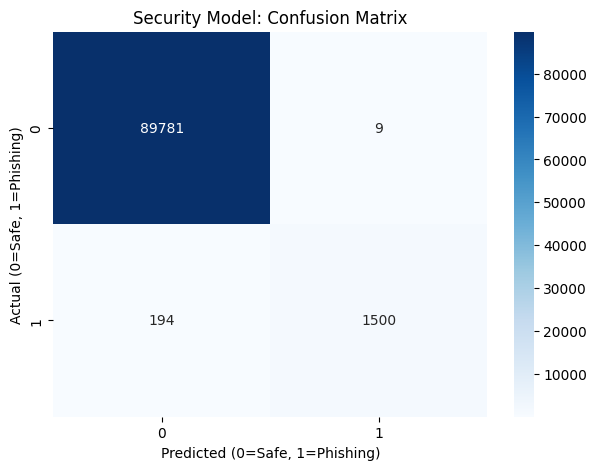

In [14]:
from sklearn.metrics import classification_report, confusion_matrix

# 1. Prediction 
y_pred = model.predict(X_test)

# 2. Detailed Metrics
print("--- Phishing Detection Performance Report ---")
print(classification_report(y_test, y_pred))

# 3. Visualization
plt.figure(figsize=(7,5))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted (0=Safe, 1=Phishing)')
plt.ylabel('Actual (0=Safe, 1=Phishing)')
plt.title('Security Model: Confusion Matrix')
plt.show()

--- Final Model Performance ---
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     89790
           1       0.99      0.89      0.94      1694

    accuracy                           1.00     91484
   macro avg       1.00      0.94      0.97     91484
weighted avg       1.00      1.00      1.00     91484



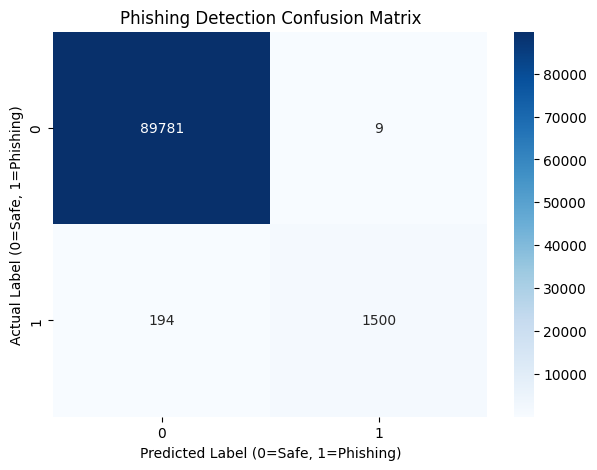

In [15]:
from sklearn.metrics import classification_report, confusion_matrix

# 1. Ask the AI to predict the test set (This part will be very fast!)
y_pred = model.predict(X_test)

# 2. See the accuracy and detail
print("--- Final Model Performance ---")
print(classification_report(y_test, y_pred))

# 3. Create the Heatmap (Confusion Matrix)
plt.figure(figsize=(7,5))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted Label (0=Safe, 1=Phishing)')
plt.ylabel('Actual Label (0=Safe, 1=Phishing)')
plt.title('Phishing Detection Confusion Matrix')
plt.show()

In [ ]:
import joblib

# Save the model and the vectorizer
joblib.dump(model, 'phishing_detector_model.pkl')
joblib.dump(tfidf, 'tfidf_vectorizer.pkl')

print(" Model and Vectorizer saved successfully! You won't need to wait 8 minutes again.")

✅ Model and Vectorizer saved successfully! You won't need to wait 8 minutes again.


In [19]:
def predict_email(new_email):
    # 1. Clean the input just like we cleaned the training data
    cleaned_email = clean_text(new_email)
    
    # 2. Vectorize the input
    vectorized_email = tfidf.transform([cleaned_email])
    
    # 3. Predict
    prediction = model.predict(vectorized_email)
    
    if prediction[0] == 1:
        return " WARNING: This looks like a Phishing attempt!"
    else:
        return " This email seems Safe."

# Test it out with a suspicious message
test_message = "Urgent: Your account has been suspended. Click here to verify your login immediately or your data will be deleted."
print(f"Result: {predict_email(test_message)}")

Result:  This email seems Safe.
